# Create an Import model with code

Same tables, same relationships, same measures as the Direct Lake model,
but Import. There is no generate function for this one: blank model,
then tables, columns and partitions built from the Spark schemas.

Why bother? Import populates all the DMV statistics that stay empty
on Direct Lake. That comparison is the whole point.

Prerequisites: run the lakehouse prep notebook first (DimDate), and attach the environment with semantic-link-labs.

In [1]:
# Setup: sempy reads and analyzes models, sempy_labs creates and changes them.
# sempy_labs comes from the attached environment, so no %pip install needed.

import sempy.fabric as fabric
import sempy_labs as labs
from sempy_labs.tom import connect_semantic_model
from sempy.relationships import plot_relationship_metadata
from importlib.metadata import version

print(f"semantic-link-labs {version('semantic-link-labs')}")

WORKSPACE = "Dataminds DEV"
DATASET = "SM_Contoso_Import"
LAKEHOUSE = "LH_Contoso"

TABLES = [
    "DimCustomer",
    "DimProduct",
    "DimProductCategory",
    "DimProductSubcategory",
    "DimStore",
    "FactOnlineSales",
    "DimDate",
]

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 21, Finished, Available, Finished, False)

semantic-link-labs 0.17.1


## Read the schemas from the lakehouse

No manual column definitions. Spark knows the schema, so the model
builds itself from metadata.

In [2]:
# Read the column definitions from the lakehouse instead of typing them by hand,
# and translate the Spark data types to Tabular data types.

SPARK_TO_TOM = {
    "LongType": "Int64", "IntegerType": "Int64", "ShortType": "Int64", "ByteType": "Int64",
    "StringType": "String",
    "TimestampType": "DateTime", "DateType": "DateTime",
    "DoubleType": "Double", "FloatType": "Double",
    "DecimalType": "Decimal",
    "BooleanType": "Boolean",
}

schemas = {
    t: [(f.name, SPARK_TO_TOM.get(type(f.dataType).__name__, "String"))
        for f in spark.table(f"{LAKEHOUSE}.dbo.{t}").schema.fields]
    for t in TABLES
}

for t, cols in schemas.items():
    print(t, "→", len(cols), "columns")

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 22, Finished, Available, Finished, False)

DimCustomer → 12 columns
DimProduct → 8 columns
DimProductCategory → 2 columns
DimProductSubcategory → 3 columns
DimStore → 3 columns
FactOnlineSales → 9 columns
DimDate → 7 columns


## Build the model

Blank model first, then per table: the table object, every column,
and an Import partition.

Partitions use Lakehouse.Contents, the Fabric-native connector, same route Dataflows use.
First attempt was Sql.Database via the SQL endpoint: connection dialogs, credentials, misery.
This one just needs a one-time OAuth on the Lakehouse source
(model settings > Data source credentials, after every rebuild).

In [3]:
# There is no generate function for Import, so we start with an empty model.

labs.create_blank_semantic_model(dataset=DATASET, workspace=WORKSPACE, overwrite=True)

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 23, Finished, Available, Finished, False)

🟢 The 'SM_Contoso_Import' semantic model was created within the 'Dataminds DEV' workspace.


'd8448b3c-95a2-4c30-bcec-40006d35f1b2'

In [4]:
# Per table: the table, its columns and an Import partition.
# The partition loads the data via Lakehouse.Contents, the Fabric-native connector.

with connect_semantic_model(dataset=DATASET, workspace=WORKSPACE, readonly=False) as tom:
    for t, cols in schemas.items():
        tom.add_table(name=t)

        for col_name, col_type in cols:
            tom.add_data_column(table_name=t, column_name=col_name,
                                source_column=col_name, data_type=col_type)

        m_expression = f'''let
    Source = Lakehouse.Contents(null),
    Ws = Source{{[workspaceName = "{WORKSPACE}"]}}[Data],
    Lh = Ws{{[lakehouseName = "{LAKEHOUSE}"]}}[Data],
    Tbl = Lh{{[Id = "{t}", ItemKind = "Table"]}}[Data]
in
    Tbl'''

        tom.add_m_partition(table_name=t, partition_name=t,
                            expression=m_expression, mode="Import")

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 24, Finished, Available, Finished, False)

## Relationships

Identical to the Direct Lake model. Same code, different model —
that's the whole point of modeling with code.

In [5]:
# Same relationships as the Direct Lake model: same code, different storage mode.

rels = [
    ("FactOnlineSales", "ProductKey", "DimProduct", "ProductKey"),
    ("FactOnlineSales", "CustomerKey", "DimCustomer", "CustomerKey"),
    ("FactOnlineSales", "StoreKey", "DimStore", "StoreKey"),
    ("FactOnlineSales", "DateKey", "DimDate", "DateKey"),
    ("DimProduct", "ProductSubcategoryKey", "DimProductSubcategory", "ProductSubcategoryKey"),
    ("DimProductSubcategory", "ProductCategoryKey", "DimProductCategory", "ProductCategoryKey"),
]

with connect_semantic_model(dataset=DATASET, workspace=WORKSPACE, readonly=False) as tom:
    for from_table, from_col, to_table, to_col in rels:
        tom.add_relationship(
            from_table=from_table,
            from_column=from_col,
            to_table=to_table,
            to_column=to_col,
            from_cardinality="Many",
            to_cardinality="One",
            cross_filtering_behavior="OneDirection",
        )
    tom.mark_as_date_table(table_name="DimDate", column_name="DateKey")

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 25, Finished, Available, Finished, False)

🟢 The 'DimDate' table has been marked as a date table using the 'DateKey' column as its primary date key.


## Measure table, measures and the UDF

Same enrichment as the Direct Lake model, added before the refresh,
so one processing run covers everything (including the calculated table).

In [6]:
# Measure table, measures and UDF before the refresh,
# so one processing run also covers the calculated table.

measures = [
    ("Total Sales", "SUMX(FactOnlineSales, FactOnlineSales[SalesQuantity] * FactOnlineSales[UnitPrice])", "#,0.00", "Revenue: quantity times unit price"),
    ("Total Cost",  "SUMX(FactOnlineSales, FactOnlineSales[SalesQuantity] * FactOnlineSales[UnitCost])",  "#,0.00", "Total cost of goods sold"),
    ("Margin %",    "DIVIDE([Total Sales] - [Total Cost], [Total Sales])",                                "0.0%",   "Gross margin as a percentage of sales"),
]

with connect_semantic_model(dataset=DATASET, workspace=WORKSPACE, readonly=False) as tom:
    tom.add_calculated_table(name="_Measures", expression='ROW("Dummy", BLANK())')

with connect_semantic_model(dataset=DATASET, workspace=WORKSPACE, readonly=False) as tom:
    tom.model.Tables["_Measures"].Columns["Dummy"].IsHidden = True
    for name, expr, fmt, desc in measures:
        tom.add_measure(table_name="_Measures", measure_name=name, expression=expr,
                        format_string=fmt, description=desc)

    print("Compatibility level:", tom.model.Database.CompatibilityLevel)
    tom.set_user_defined_function(
        name="SafeMargin",
        expression="(sales: SCALAR, cost: SCALAR) => DIVIDE(sales - cost, sales)",
    )
    tom.add_measure(
        table_name="_Measures",
        measure_name="Margin % (UDF)",
        expression="SafeMargin([Total Sales], [Total Cost])",
        format_string="0.0%",
        description="Margin via user-defined function",
    )

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 26, Finished, Available, Finished, False)

Compatibility level: 1702


## Refresh = processing

This is the real difference with Direct Lake. This refresh reads all 12.6M rows
and compresses them into the model. Minutes, not seconds.

First run after a rebuild: set the Lakehouse credentials (OAuth) in the model settings first.

In [7]:
# Import refresh = processing: all 12.6M rows are read and compressed into the model.
# This is the big difference with Direct Lake. Minutes, not seconds.

labs.refresh_semantic_model(dataset=DATASET, workspace=WORKSPACE, refresh_type="full")

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 27, Finished, Available, Finished, False)

⌛ Refresh of the 'SM_Contoso_Import' semantic model within the 'Dataminds DEV' workspace is in progress...
🟢 Refresh 'full' of the 'SM_Contoso_Import' semantic model within the 'Dataminds DEV' workspace is complete.


## Verify

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 28, Finished, Available, Finished, False)

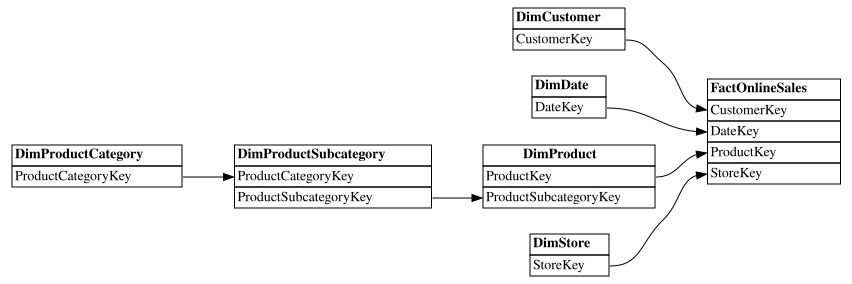

In [8]:
# Check the relationships. Sempy caches metadata, so refresh the cache first.

fabric.refresh_tom_cache(workspace=WORKSPACE)
plot_relationship_metadata(fabric.list_relationships(DATASET, workspace=WORKSPACE))

In [9]:
# Test with a DAX query: the numbers must match the Direct Lake model exactly.

fabric.evaluate_dax(DATASET, workspace=WORKSPACE, dax_string="""
EVALUATE
SUMMARIZECOLUMNS(
    DimDate[Year],
    "Total Sales", [Total Sales],
    "Margin classic", [Margin %],
    "Margin via UDF", [Margin % (UDF)]
)
""")

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 29, Finished, Available, Finished, False)

,DimDate[Year],[Total Sales],[Margin classic],[Margin via UDF]
0,2007,1108917269.99,0.577027,0.577027
1,2008,934403814.178,0.568747,0.568747
2,2009,940877836.936,0.569861,0.569861
